## This notebook analyzes the RMSE errors between SWOT and the model results in relation to the TPXO predicted water level

In [11]:
#import arcpy
import os
import csv
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import glob
from datetime import datetime
import numpy as np
import scipy.stats as ss
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr
import matplotlib as mpl

In [12]:
#rmse_s from swot and anuga pixel comparisions file
data = pd.read_csv('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/swot_anuga_tpxo_bias_rmse.csv')

#tpxo predicted water levels
tpxo_hr = pd.read_csv('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT MODEL comparisons/tpxo_4_10-4_15_2023.csv')

In [13]:
#converts date column to datetime
data['anuga_time'] = pd.to_datetime(data['anuga_time'])  # auto-infers format
data.set_index('anuga_time', inplace=True)

data.head()

/var/folders/9f/0j2vxc3d2fg6zlqyvz4p32nm0000gq/T/ipykernel_17110/3170011937.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['anuga_time'] = pd.to_datetime(data['anuga_time'])  # auto-infers format


,swot_time,tpxo_wl_swot,tpxo_wl_anuga,bias_s_a,mae_s_a,rmse_s_a,corr_s_a
anuga_time,,,,,,,
2023-04-10 09:21:00,4/10/23 9:21,-0.142292,-0.142292,0.254,0.254,0.266,0.889
2023-04-11 09:11:00,4/11/23 9:11,0.111609,0.111609,0.155,0.157,0.171,0.887
2023-04-12 09:01:00,4/12/23 9:02,0.273396,0.275197,0.105,0.113,0.131,0.735
2023-04-13 08:51:00,4/13/23 8:53,0.306155,0.305189,0.058,0.083,0.106,0.059
2023-04-14 08:41:00,4/14/23 8:43,0.194000,0.189055,0.002,0.072,0.100,0.645


In [14]:
tpxo_hr['datetime'] = pd.to_datetime(tpxo_hr['datetime'])  # auto-infers format
tpxo_hr.set_index('datetime', inplace=True)

tpxo_hr.head()
#tpxo_hr.to_csv('test.csv')

/var/folders/9f/0j2vxc3d2fg6zlqyvz4p32nm0000gq/T/ipykernel_17110/2640508397.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  tpxo_hr['datetime'] = pd.to_datetime(tpxo_hr['datetime'])  # auto-infers format


,time,wl
datetime,,
2023-04-10 09:00:00,810055,-0.040330
2023-04-10 09:01:00,810115,-0.045194
2023-04-10 09:02:00,810175,-0.050060
2023-04-10 09:03:00,810235,-0.054927
2023-04-10 09:04:00,810295,-0.059795


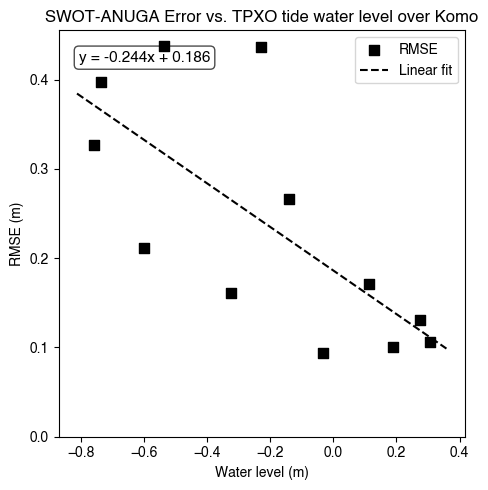

In [15]:
mpl.rcParams["font.family"] = "Helvetica"
plt.figure(figsize=(5, 5))


plt.scatter(data["tpxo_wl_anuga"], data["rmse_s_a"],color='black', s=50,zorder=5, label='RMSE', marker='s')#, color='red', zorder=5, label='Acquisition')

# Linear regression fit
slope, intercept = np.polyfit(data["tpxo_wl_anuga"], data["rmse_s_a"], deg=1)
x_vals = np.array(plt.gca().get_xlim())
y_vals = slope * x_vals + intercept
plt.plot(x_vals, y_vals, 'k--', lw=1.5, label='Linear fit')

# Add equation as text
equation = f"y = {slope:.3f}x + {intercept:.3f}"
plt.text(0.05, 0.95, equation, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.7))
plt.ylim(bottom=0)
plt.gca().set_box_aspect(1)  
plt.ylabel("RMSE (m)")
plt.xlabel("Water level (m)")
plt.legend()
plt.title("SWOT-ANUGA Error vs. TPXO tide water level over Komo")
#plt.grid(True)
plt.tight_layout()
plt.savefig("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/bias_rmse_overall_swot.pdf")
plt.show()

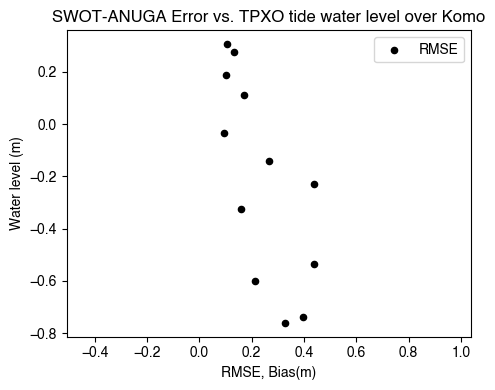

In [16]:
mpl.rcParams["font.family"] = "Helvetica"
plt.figure(figsize=(5, 4))

#plt.plot(data["tpxo_wl_anuga"],data["anuga_time"],  color='blue', label='TPXO tide', linewidth=2)
plt.scatter( data["rmse_s_a"],data["tpxo_wl_anuga"],color='black', s=20,zorder=5, label='RMSE')#, color='red', zorder=5, label='Acquisition')

plt.axis('equal')

plt.ylabel("Water level (m)")
plt.xlabel("RMSE, Bias(m)")
plt.legend()
plt.title("SWOT-ANUGA Error vs. TPXO tide water level over Komo")
#plt.grid(True)
plt.tight_layout()
plt.show()

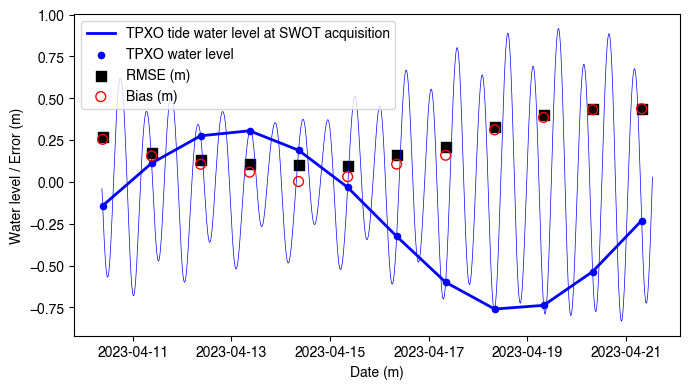

In [17]:
mpl.rcParams["font.family"] = "Helvetica"
plt.figure(figsize=(7, 4))

plt.plot(tpxo_hr.index,tpxo_hr["wl"],  color='blue', linewidth=0.5)
plt.plot(data.index, data["tpxo_wl_anuga"],  color='blue', linewidth=2, label="TPXO tide water level at SWOT acquisition")
plt.scatter(data.index,data["tpxo_wl_anuga"],s=20,  color='blue', label='TPXO water level', linewidth=1.)
plt.scatter(data.index, data["rmse_s_a"],color='black', s=50,zorder=1, label='RMSE (m)', marker='s')#, color='red', zorder=5, label='Acquisition')

plt.scatter(data.index, data["bias_s_a"],edgecolors='red', s=50,zorder=2,marker='o', label='Bias (m)',facecolors='none')


plt.ylabel("Water level / Error (m)")
plt.xlabel("Date (m)")
plt.legend()

plt.tight_layout()
plt.savefig("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/rmse_bias3.pdf")
plt.show()

In [18]:
#Computing the correlation between between the rmse errors and predicted water level.
wl = data['tpxo_wl_anuga']
rmse = data['rmse_s_a']

diff = wl - rmse

mae = mean_absolute_error(wl, rmse)
mb = ((wl - rmse).sum()) / len(rmse)
rho, pval = pearsonr(rmse, wl)
rmse = np.sqrt((diff**2).mean())


print(f'MAE (m): {mae:.3f}')
print(f'Bias (m): {mb:.3f}')
print(f'Pearson r: {rho:.3f}', f'p-val: {pval:.3f}')
print(f'RMSE (m): {rmse:.3f}')

MAE (m): 0.516
Bias (m): -0.444
Pearson r: -0.713 p-val: 0.009
RMSE (m): 0.646
